# Lab 2: Posterior and Posterior Predictive Simulation

This lab is adapted from AM207 (Harvard). Data files are in the book's `data/` folder. Worked solutions are collapsed: try each exercise before expanding them.

::::{admonition} In this lab
:class: tip

1. Exploring the Beta Prior
2. Exploring the Beta-Binomial Model
3. Exploring the Normal-Normal Model
::::

In [2]:
### Import basic libraries
import numpy as np
import scipy as sp
import pandas as pd
import sklearn as sk
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
%matplotlib inline

## The Beta Prior
In the beta-binomial model
$$\begin{aligned}
Y &\sim Bin(N, \theta)\\
\theta &\sim Beta(\alpha, \beta)
\end{aligned}$$
the beta distribution represents our prior belief about the parameter $\theta$. 

Using the code for visualizing the beta pdf to experiment with different values of $\alpha, \beta$, make a specific conjecture about how the hyperparameters $\alpha, \beta$ effect the shape of the pdf.

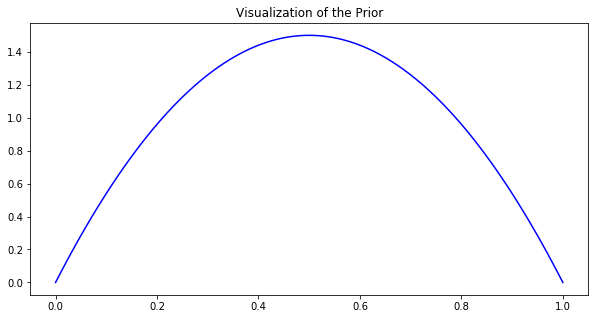

In [46]:
#prior definition: beta distribution
alpha = 2
beta = 2

#prior definition: beta distribution
prior = sp.stats.beta(alpha, beta).pdf

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
x = np.linspace(0, 1, 100)
ax.plot(x, prior(x), color='blue')
ax.set_title('Visualization of the Prior')
plt.show()

## The Beta-Binomial Posterior and Posterior Predictive
Say that you generated the data using 10 flips of a coin whose probability of heads is $\theta = 0.3$. 

1. Visualize the posterior distribution given this data.
2. Using the code for visualizing the beta pdf to experiment with different values of $\alpha, \beta$, make a specific conjecture about how the hyperparameters $\alpha, \beta$ effect the posterior distribution.
3. Make an argument for how best to choose values of $\alpha, \beta$.
4. Simulate data from the posterior predictive. Compare the posteior predictive and the observed data. What does this comparison say about your model?

::::{admonition} Solution: Question 1
:class: dropdown

```python
#data: binomial distribution
N = 10
theta = 0.3
#sample data
H = np.random.binomial(N, theta)
```

```python
#prior definition: beta distribution
alpha = 0.5
beta = 0.5
prior = sp.stats.beta(alpha, beta).pdf

#update posterior: beta distribution
posterior_alpha = H + alpha
posterior_beta = N - H + beta
posterior = sp.stats.beta(posterior_alpha, posterior_beta).pdf

fig, ax = plt.subplots(1, 2, figsize=(20, 8))
x = np.linspace(0, 1, 100)
ax[0].plot(x, prior(x), color='blue')
ax[0].set_title('Prior distribution')
ax[1].plot(x, posterior(x), color='red')
ax[1].set_title('Posterior distribution after seeing {} Heads/{} Flips'.format(H, N))
plt.show()
```

```{image} ../figures/solutions/lab-02-posterior-simulation/question-1-1.png
:alt: Question 1, figure 1
:width: 100%
:align: center
```
::::

::::{admonition} Solution: Question 4
:class: dropdown

```python
#sample from the posterior
posterior_samples = np.random.beta(posterior_alpha, posterior_beta, size=500)
#predict a number of heads with each sample of theta from the posterior
posterior_pred = [np.random.binomial(N, theta_sample, 1)[0] for theta_sample in posterior_samples]

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
#plot the observed number of heads
ax.axvline(x=H, color='black', label='observed heads')
#plot the posterior predictive about the number of heads as a histogram
ax.hist(posterior_pred, bins=50, color='red', alpha=0.6, label='histogram of predicted head')
ax.set_xticks(range(np.max(posterior_pred) + 1))
ax.set_title('posterior predictive over heads')
ax.legend(loc='best')
plt.show()
```

```{image} ../figures/solutions/lab-02-posterior-simulation/question-4-1.png
:alt: Question 4, figure 1
:width: 100%
:align: center
```

*Not covered here: what the comparison says about the model.*
::::

## The Normal-Normal Model
1. Generate $N=50$ data points from $\mathcal{N}\left( 3, 5\right)$. Visualize their empirical distribution.
2. Set your likelihood to be $Y_n \sim \mathcal{N}(\mu, 5)$. In this case, we are going to make inference about the mean $\mu$. Choose a normal prior for $\mu$, $\mu \sim\mathcal{N}(-1, 0.5)$ and visualize the posterior over $\mu$.
3. Sample $N=50$ points from your posterior predictive. Compare the empirical distribution of the observed data with that of the posterior predictive. What does this comparison say about your model?
4. Repeat this experiment different values of $N$ (some very small, some large). Make a conjecture about the relationship between $N$ and the posterior and posterior predictive distributions of this model.

::::{admonition} Solution: Questions 1-2
:class: dropdown

Recall that for the model

$$\begin{aligned}
Y_n &\sim\mathcal{N}(\mu, \sigma^2)\\
\mu &\sim \mathcal{N}(m, s^2)
\end{aligned}$$

the posterior $p(\mu|Y_1, \ldots Y_n)$ is a normal distribution

$$
\mathcal{N}\left( \frac{s^2\sum_{n=1}^N y_n + \sigma^2 m}{Ns^2 + \sigma^2}, \frac{s^2\sigma^2}{Ns^2 + \sigma^2}\right)
$$

```python
#generate data
N = 50
data = np.random.normal(3, 5**0.5, size=N)

#define the parameters of the posterior
s_squared = 0.5
m = -1
sigma_squared = 5
mean = (data.sum() * s_squared + sigma_squared * m) / (N * s_squared + sigma_squared)
variance = sigma_squared * s_squared / (N * s_squared + sigma_squared)

#define the posterior pdf
posterior_normal = sp.stats.norm(loc=mean, scale=variance**0.5)
posterior_pdf = posterior_normal.pdf

#plot the posterior pdf
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
x = np.linspace(data.min()-1, data.max()+1, 100)
ax.plot(x, posterior_pdf(x), color='red', label='posterior distribution')
ax.set_xlabel('mu')
ax.set_title('Posterior over mu')
ax.legend(loc='best')
plt.show()
```

```{image} ../figures/solutions/lab-02-posterior-simulation/questions-1-2-1.png
:alt: Questions 1-2, figure 1
:width: 100%
:align: center
```
::::

::::{admonition} Solution: Question 3
:class: dropdown

```python
number_of_samples = 1000
#sample from the posterior
posterior_samples = np.random.normal(mean, variance**0.5, size=number_of_samples)
#generate samples from the posterior predictive
posterior_predictive_samples = [np.random.normal(sample, sigma_squared**0.5) for sample in posterior_samples]


fig, ax = plt.subplots(1, 1, figsize=(10, 8))
x = np.linspace(data.min()-1, data.max()+1, 100)
#plot the observed data
ax.hist(data, bins=10, density=True, color='grey', alpha=0.3, label='empirical data distribution')
#plot the posterior predictive 
ax.hist(posterior_predictive_samples, density=True, bins=50, color='red', alpha=0.2, label='posterior predictive')
ax.set_title('Empirical Distribution of Data vs the Posterior Predictive')
ax.legend(loc='best')
plt.show()
```

```{image} ../figures/solutions/lab-02-posterior-simulation/question-3-1.png
:alt: Question 3, figure 1
:width: 100%
:align: center
```

*Not covered here: what the comparison says about the model.*
::::